# Second Practice
### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336
##### We have been able to cooperate during the whole practice, very little individual work

In [3]:
# Necessary libraries
import numpy as np
import matplotlib.pyplot as plt

## 1. Gradient descent methods

### 1.1 A simple quadratic function

We will define $f$ as:
$$
    f(x)=x_{1}^{2} + x_{2}^{2}
$$

By derivating, we obtain the gradient:
$$
    \nabla f(x) = (2x_{1}, 2x_{2})
$$

Now we perform the next experiments

#### 1.1.1 Implement gradient descent with a constant $\alpha^{k} = 0.1$.

In [46]:
def grad_desc(f, grad_f, x0, alpha, max_iter):
    x=x0
    counter = 0
    for i in range(max_iter):
        counter += 1
        x = x -alpha * grad_f(x)
    return x, f(x)

def f(x): return x[0]**2 + x[1]**2
def grad_f(x): return np.array([2*x[0], 2*x[1]])

In [81]:
x0 = np.random.uniform(-200, 200, 2)

x_final, f_final = grad_desc(f, grad_f, x0, alpha=0.1, max_iter=100)

print(f"x    = [{x_final[0]:.2e}, {x_final[1]:.2e}]")
print(f"f(x) = {f_final:.2e}")


x    = [2.46e-08, 3.35e-09]
f(x) = 6.15e-16


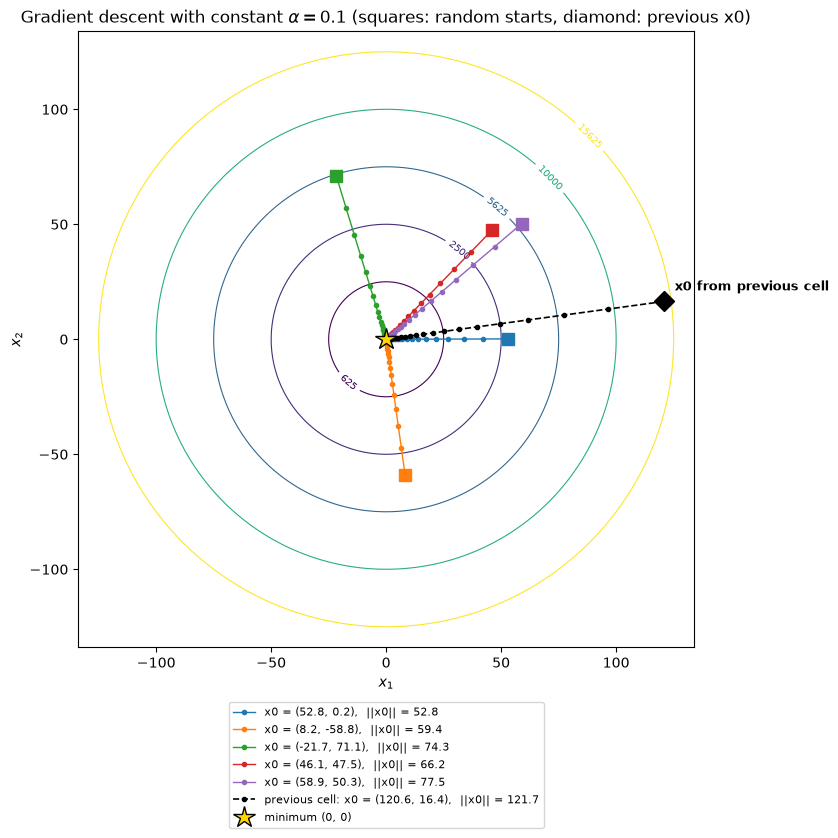

In [82]:
# MADE WITH AI

def grad_desc_path(grad_f, x0, alpha, max_iter):
    # Same iteration as grad_desc, but keeps every point to draw the trajectory
    x = x0
    path = [x]
    for i in range(max_iter):
        x = x - alpha * grad_f(x)
        path.append(x)
    return np.array(path)

# 5 random starting points at a distance between 30 and 100 from (0, 0)
r = np.random.uniform(30, 100, 5)
theta = np.random.uniform(0, 2*np.pi, 5)
starts = np.column_stack([r*np.cos(theta), r*np.sin(theta)])

# The x0 from the previous cell can be further away, so the plot limits adapt to it
lim = 1.1 * max(100, np.linalg.norm(x0))
step = 10 if lim <= 120 else 25

# Contour lines of f (circles of radius step, 2*step, ...)
X, Y = np.meshgrid(np.linspace(-lim, lim, 400), np.linspace(-lim, lim, 400))
Z = f(np.array([X, Y]))

fig, ax = plt.subplots(figsize=(8, 8))
cs = ax.contour(X, Y, Z, levels=[k**2 for k in np.arange(step, lim, step)], cmap="viridis", linewidths=0.8)
ax.clabel(cs, fontsize=7, fmt="%.0f")

colors = plt.cm.tab10.colors
for i, start in enumerate(starts):
    path = grad_desc_path(grad_f, start, alpha=0.1, max_iter=100)
    ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
            label=f"x0 = ({start[0]:.1f}, {start[1]:.1f}),  ||x0|| = {np.linalg.norm(start):.1f}")
    ax.plot(*start, "s", color=colors[i], ms=9)

# x0 from the previous cell, drawn in black with a dashed line and a diamond
path = grad_desc_path(grad_f, x0, alpha=0.1, max_iter=100)
ax.plot(path[:, 0], path[:, 1], "--o", color="k", ms=3, lw=1.2,
        label=f"previous cell: x0 = ({x0[0]:.1f}, {x0[1]:.1f}),  ||x0|| = {np.linalg.norm(x0):.1f}")
ax.plot(*x0, "D", color="k", ms=10)
ax.annotate("x0 from previous cell", x0, xytext=(8, 8), textcoords="offset points", fontsize=9, weight="bold")

ax.plot(0, 0, "*", color="gold", mec="k", ms=16, label="minimum (0, 0)")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title(r"Gradient descent with constant $\alpha = 0.1$ (squares: random starts, diamond: previous x0)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.show()

#### 1.1.2 Try gain with $\alpha^{k} = 1$ and $\alpha^{k} = 2$

In [84]:
x_final_1, f_final_1 = grad_desc(f, grad_f, x0, alpha=1, max_iter=100)

print(f"x    = [{x_final_1[0]:.2e}, {x_final_1[1]:.2e}]")
print(f"f(x) = {f_final_1:.2e}")

x_final_2, f_final_2 = grad_desc(f, grad_f, x0, alpha=2, max_iter=100)

print(f"x    = [{x_final_2[0]:.2e}, {x_final_2[1]:.2e}]")
print(f"f(x) = {f_final_2:.2e}")

x    = [1.21e+02, 1.64e+01]
f(x) = 1.48e+04
x    = [6.22e+49, 8.47e+48]
f(x) = 3.94e+99


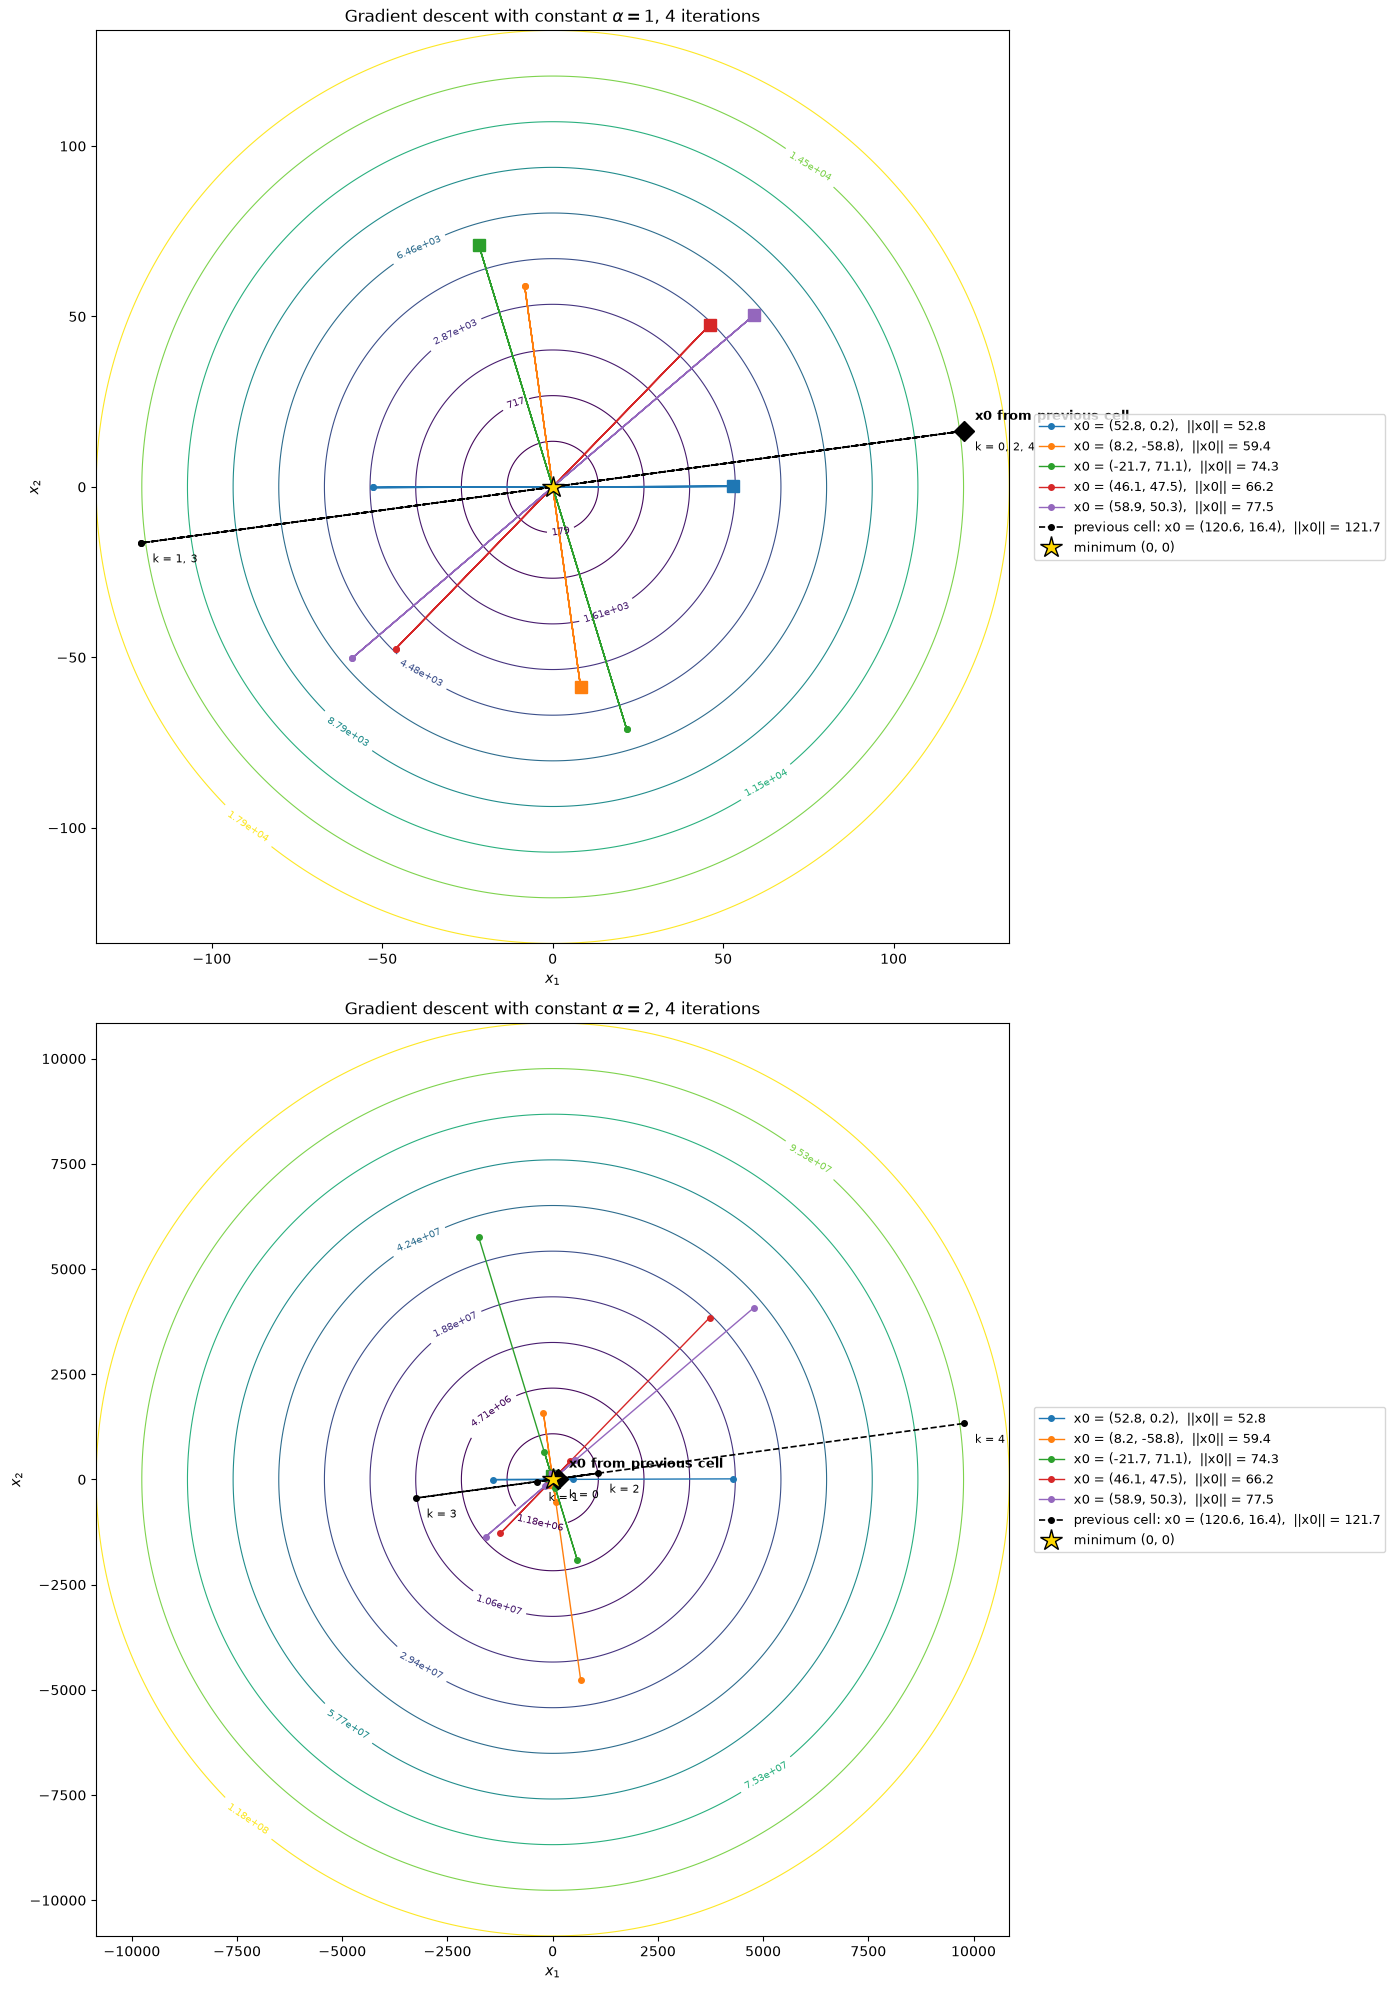

In [86]:
# MADE WITH AI

# Same plot as in 1.1.1 (same 5 random starts and x0 from cell 7), now with alpha = 1 and alpha = 2, 4 iterations
fig, axes = plt.subplots(2, 1, figsize=(12, 20))
colors = plt.cm.tab10.colors

for ax, alpha in zip(axes, [1, 2]):
    paths = [grad_desc_path(grad_f, start, alpha=alpha, max_iter=4) for start in starts]
    path_prev = grad_desc_path(grad_f, x0, alpha=alpha, max_iter=4)

    # Plot limits and contour lines adapt to how far the iterates go
    lim = 1.1 * max(np.linalg.norm(p, axis=1).max() for p in paths + [path_prev])
    X, Y = np.meshgrid(np.linspace(-lim, lim, 400), np.linspace(-lim, lim, 400))
    Z = f(np.array([X, Y]))
    cs = ax.contour(X, Y, Z, levels=np.linspace(0, lim, 11)[1:]**2, cmap="viridis", linewidths=0.8)
    ax.clabel(cs, fontsize=7, fmt="%.3g")

    for i, (start, path) in enumerate(zip(starts, paths)):
        ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=4, lw=1,
                label=f"x0 = ({start[0]:.1f}, {start[1]:.1f}),  ||x0|| = {np.linalg.norm(start):.1f}")
        ax.plot(*start, "s", color=colors[i], ms=9)

    # x0 from the previous cell, drawn in black with a dashed line and a diamond
    ax.plot(path_prev[:, 0], path_prev[:, 1], "--o", color="k", ms=4, lw=1.2,
            label=f"previous cell: x0 = ({x0[0]:.1f}, {x0[1]:.1f}),  ||x0|| = {np.linalg.norm(x0):.1f}")
    ax.plot(*x0, "D", color="k", ms=10)
    ax.annotate("x0 from previous cell", x0, xytext=(8, 8), textcoords="offset points", fontsize=9, weight="bold")

    # Iteration number of each point of the black path (points that coincide share one label)
    labels = {}
    for k, p in enumerate(path_prev):
        labels.setdefault(tuple(np.round(p, 6)), []).append(str(k))
    for p, ks in labels.items():
        ax.annotate("k = " + ", ".join(ks), p, xytext=(8, -14), textcoords="offset points", fontsize=8)

    ax.plot(0, 0, "*", color="gold", mec="k", ms=16, label="minimum (0, 0)")
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(rf"Gradient descent with constant $\alpha = {alpha}$, 4 iterations")
    ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
plt.show()